 ДЗ «Отбор переменных» 10 баллов + 2 бонус

# О формате сдачи

🔷 **<font color='plum'>При решении ноутбука используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, обычно помечаются фразами "Your code here"/"Ваш код" и аналогичными
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличе работоспособного кода в ноутбуке, если на сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, обычно помечаются фразами Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Обычно выводы подразумевают под собой текстовый ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблички - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл

Продолжаем работать с задачей из семинара «Генерация признаков». Мы предсказывали, с какой вероятностью клиент отменит заказ такси, и создали для этого множество переменных. Но не все из них оказались полезными для качества решения задачи, поэтому в этом дз будем отбирать переменные.


В этом ДЗ ты самостоятельно попробуешь:


- отбрать переменные;
- посмотришь чем отличаются алгоритмы отбора переменных;
- поймешь как использовать фильтры, обёртки и встроенные методы.


Для решения задачи рассмотрим алгоритмы отбора.
* Фильтры используют статистические метрики для оценки информативности признаков дообучения модели.
* Обёртки выполняют отбор, итеративно обучая модель и оценивая качество на разных наборах признаков.
* Встренные методы позволяют получать значения важности сразу всех признаков вместе с обучением модели.

## Подготовка

Загрузим обработанный датасет с семинара, импортируем библиотеки и определим необходимые функции.

In [5]:
# Загружаем датасеты
!gdown 1SZ-yolvKz4P-dxWcF0DMWSciijtNF6ZV
!gdown 1mtoJAqB4Mxh8K6K-9IkkoYMWxcoysZQy

Downloading...
From: https://drive.google.com/uc?id=1SZ-yolvKz4P-dxWcF0DMWSciijtNF6ZV
To: /content/df_train.parquet
100% 90.5M/90.5M [00:01<00:00, 63.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=1mtoJAqB4Mxh8K6K-9IkkoYMWxcoysZQy
To: /content/df_test.parquet
100% 20.1M/20.1M [00:00<00:00, 60.1MB/s]


In [6]:
# Импортируем необходимые пакеты
import time

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score

from lightgbm import LGBMClassifier # Берём lightgbm — одну из самых популярных реализаций бустинга



Наша цель — посмотреть на основные методы отбора. Для этого используем LightGBM — быструю и эффективную библиотеку для градиентного бустинга на деревьях решений.

Также можно использовать библиотеки CatBoost и XGBoost и различные не бустинговые алгоритмы.






In [7]:
# Считаем датасеты
df_train = pd.read_parquet('/content/df_train.parquet')
df_test = pd.read_parquet('/content/df_test.parquet')

In [8]:
df_train

,dist,due,lat,lon,target,econom,business,vip,holiday,weekend,...,temperature_diff_3,apparent_temperature_diff_3,temperature_4,apparent_temperature_4,temperature_diff_4,apparent_temperature_diff_4,temperature_5,apparent_temperature_5,temperature_diff_5,apparent_temperature_diff_5
0,17990.125431,2014-01-01 00:09:32,55.750130,37.823242,1,True,False,False,True,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2322.180999,2014-01-01 00:10:00,55.711488,37.884183,0,True,False,False,True,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,14608.577392,2014-01-01 00:10:00,55.633404,37.797595,0,True,False,False,True,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,20055.569096,2014-01-01 00:10:00,55.780380,37.645240,0,True,False,False,True,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,20585.444093,2014-01-01 00:10:00,55.675676,37.500387,1,True,False,False,True,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
907397,7826.933335,2014-02-21 21:10:00,55.678615,37.750532,0,True,False,False,False,False,...,0.42,0.2,-0.99,-3.79,0.4,0.67,-0.82,-3.31,0.17,0.48
907396,1499.565424,2014-02-21 21:10:00,55.786455,37.678837,0,True,True,False,False,False,...,0.42,0.2,-0.99,-3.79,0.4,0.67,-0.82,-3.31,0.17,0.48
907394,16075.004418,2014-02-21 21:10:00,55.768729,37.667519,0,True,True,False,False,False,...,0.42,0.2,-0.99,-3.79,0.4,0.67,-0.82,-3.31,0.17,0.48
907405,11478.356838,2014-02-21 21:10:00,55.674336,37.279491,1,True,False,False,False,False,...,0.42,0.2,-0.99,-3.79,0.4,0.67,-0.82,-3.31,0.17,0.48


In [9]:
# LightGBM и sklearn в данных версиях совместимы, но будет предупреждение о переименовании аргумента
# Чтобы предупреждение не мешало, отключим его
import warnings

# Игнорировать конкретное предупреждение
warnings.filterwarnings("ignore", category=FutureWarning,
                        message="'force_all_finite' was renamed to 'ensure_all_finite'")

In [10]:
# Функция для обучения и валидации модели из прошлого семинара
def learn_and_validate(lgbm_kwargs={'n_estimators': 100, 'n_jobs': -1, 'verbosity': -1, # Деревьев ставим поменьше, чтобы быстро работало. Если поставить больше, качество будет немного выше
                                    # 'device': 'gpu', # Можно использовать GPU, но так как датасет небольшой, прирост будет всего в 2 раза, а не на порядок
                                    },
                       drop_cols=['due', 'target']):
  # Инициализируем модель
  model = LGBMClassifier(**lgbm_kwargs)

  # Исключаем дату, потому что бустинг с ней не работает в чистом виде
  model.fit(df_train.drop(columns=drop_cols).values, df_train['target'].values.ravel())

  # Делаем предсказание
  preds_test = model.predict_proba(df_test.drop(columns=drop_cols).values)
  preds_train = model.predict_proba(df_train.drop(columns=drop_cols).values)

  # Считаем метрику
  roc_auc_test = roc_auc_score(df_test['target'].values.ravel(), preds_test[:, 1])
  roc_auc_train = roc_auc_score(df_train['target'].values.ravel(), preds_train[:, 1])

  print(f'ROC AUC на test равен {round(roc_auc_test, 5)}')
  print(f'ROC AUC на train равен {round(roc_auc_train, 5)}')

  return round(roc_auc_test, 5), round(roc_auc_train, 5)

Добавим небольшое изменение. Cоберём информацию по количеству переменных и скорости обучения.

In [11]:
# Результаты всех экспериментов соберём в таблице, визуализируя динамику качества по сравнению с прошлыми экспериментами
results = pd.DataFrame(index=['test', 'train'])
# Датасет, чтобы смотреть, сколько фичей отобрали и сколько времени занимает обучение
metadata = pd.DataFrame(index=['n_feats', 'time'])

start = time.time()
results['best'] = learn_and_validate(drop_cols=['due', 'target', 'city_name'] + list(df_train.columns[69:])) # Обучаем лучшую модель с прошлой недели
stop = time.time()

metadata['best'] = [66, stop-start]

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


ROC AUC на test равен 0.73905
ROC AUC на train равен 0.73436


In [12]:
# Функция для отрисовки сравнения качества экспериментов: делаем три графика рядом, чтобы сравнивать качество, количество переменных и время
def vis_results(results, metadata):
  fig, axs = plt.subplots(1, 3, figsize=(15, 6))

  colors = {'test': 'red', 'train': 'green'}

  for idx in results.index:
    axs[0].scatter([], [], color=colors[idx], label=idx)

  for column in results.columns:
      for idx in results.index:
          axs[0].scatter(column, results.loc[idx, column], color=colors[idx])

      axs[1].scatter(column, metadata.loc['n_feats', column], label=column, color='blue')
      axs[2].scatter(column, metadata.loc['time', column], label=column, color='blue')

  axs[0].set_title('AUC')
  axs[0].set_ylabel('Значение')
  axs[0].legend(title='Подвыборка')

  axs[1].set_title('Количество переменных')
  axs[1].set_ylabel('Количество (шт.)')

  axs[2].set_title('Потрачено времени')
  axs[2].set_ylabel('Время (сек.)')

  plt.tight_layout()
  plt.show()

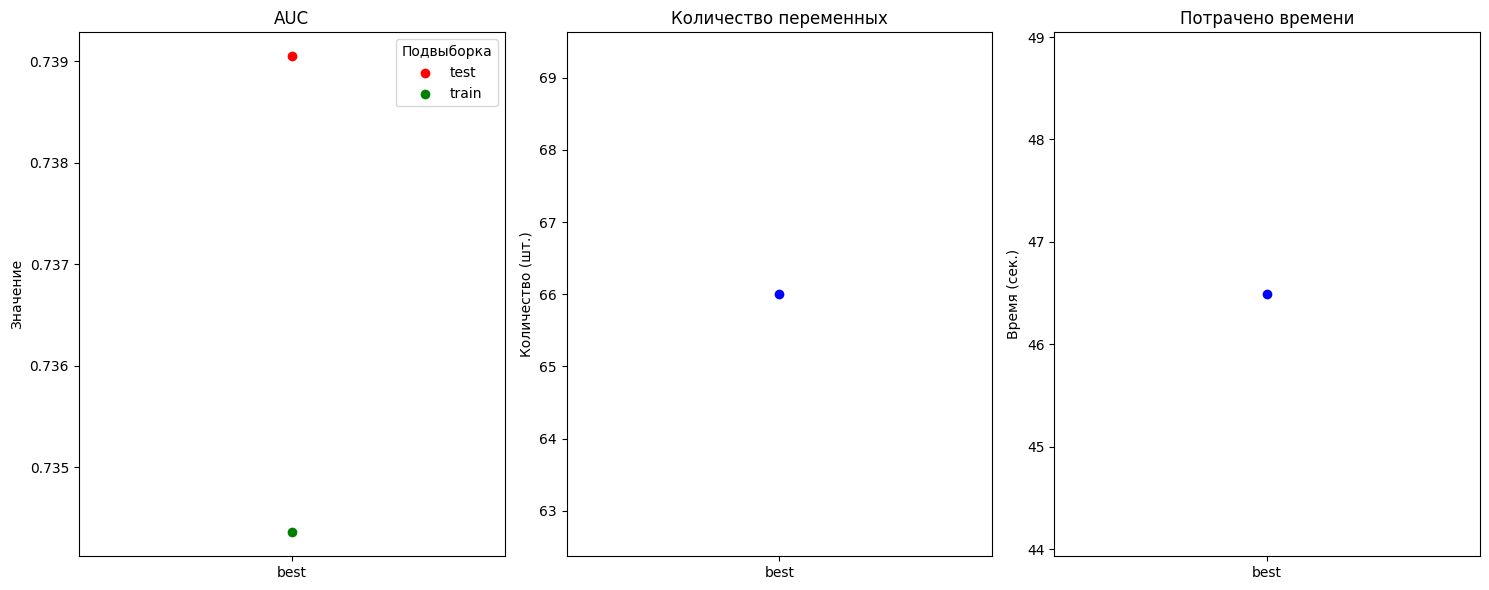

In [13]:
# Проверим, что работает
vis_results(results, metadata)

## Фильтры

> **Фильтры** используют статистические метрики для оценки информативности признаков дообучения модели.

Так как наш датасет содержит только вещественные признаки, только для них применим методы фильтрации. Заметим, что методы отбора для категориальных признаков работают аналогично.

Обрати внимание:

- методы не работают с пропущенными значениями. При большом количестве пропусков эти методы не подходят;

- в нашем случае пропусков мало, поэтому используем метод `dropna`.


Для отбора переменных с помощью фильтров можно использовать три удобные обёртки из sklearn:
- `SelectKBest` — отбирает k лучших признаков по заданному критерию;
- `SelectPercentile` — отбирает топ лучших признаков до заданного перцентиля по критерию;
- `SelectFdr` — отбирает признаки по заданному порогу p-value (количество полезных для задачи переменных заранее не фиксируется).

In [14]:
# Импортируем необходимые классы
from sklearn.feature_selection import SelectKBest, SelectFdr

Начнём с ANOVA, или, как ещё называют этот метод отбора признаков, F-теста.

In [15]:
# Применяем ANOVA
from sklearn.feature_selection import f_classif

f_statistic, p_values = f_classif(df_train.dropna().drop(columns=['due', 'target', 'city_name']), df_train.dropna()['target'])

Что получили в итоге:

- `f_statisics` — расчётное значение f-статистики. Чем она больше, тем более значим признак;
- `p_values` — вероятность принять гипотезу $H_0$ (признак незначим). Чем меньше `p_value`, тем более полезен признак для модели.

In [16]:
f_statistic

array([9.81146818e+01, 5.28265162e+02, 2.34705799e+02, 2.45875675e+01,
       1.01629766e+02, 9.70546244e+02, 1.79849414e+02, 5.58904156e-02,
       6.70948689e-01, 2.56694759e+01, 3.23585005e-01, 7.02176773e+02,
       2.70171652e+03, 2.36835590e+03, 2.64751898e+02, 1.17394132e+03,
       9.19486226e+02, 1.62238276e+02, 3.23378367e+02, 1.29680709e+03,
       1.05820411e+03, 5.43068634e+02, 2.87284682e-02, 1.93792114e+03,
       1.16301498e-01, 2.98376971e+03, 2.98087077e-01, 3.71462492e+03,
       2.17181868e-02, 4.63645255e+03, 1.03770355e-01, 5.12377298e+03,
       5.61970091e-03, 5.62102054e+03, 1.19093704e-01, 6.24662075e+03,
       3.13399376e+04, 2.99361220e+03, 1.71035896e+04, 3.13739370e+04,
       2.98853940e+03, 1.71206580e+04, 3.15774134e+04, 2.99481703e+03,
       1.70868676e+04, 3.13095834e+04, 2.99474110e+03, 1.70448002e+04,
       3.05737769e+04, 2.96432144e+03, 1.66420334e+04, 3.06961566e+04,
       2.89288520e+03, 1.66895662e+04, 2.71442149e+04, 2.63071687e+03,
      

In [17]:
p_values

array([3.96141938e-023, 7.39803430e-117, 5.71758738e-053, 7.10239234e-007,
       6.71684837e-024, 6.21986202e-213, 5.28515390e-041, 8.13113408e-001,
       4.12721308e-001, 4.05281819e-007, 5.69461283e-001, 1.18647380e-154,
       0.00000000e+000, 0.00000000e+000, 1.61817451e-059, 4.45965884e-257,
       7.56821499e-202, 3.70262033e-037, 2.75637589e-072, 9.81513951e-284,
       5.83775855e-232, 4.47625042e-120, 8.65407552e-001, 0.00000000e+000,
       7.33081052e-001, 0.00000000e+000, 5.85084308e-001, 0.00000000e+000,
       8.82839301e-001, 0.00000000e+000, 7.47351223e-001, 0.00000000e+000,
       9.40242847e-001, 0.00000000e+000, 7.30019624e-001, 0.00000000e+000,
       0.00000000e+000, 0.00000000e+000, 0.00000000e+000, 0.00000000e+000,
       0.00000000e+000, 0.00000000e+000, 0.00000000e+000, 0.00000000e+000,
       0.00000000e+000, 0.00000000e+000, 0.00000000e+000, 0.00000000e+000,
       0.00000000e+000, 0.00000000e+000, 0.00000000e+000, 0.00000000e+000,
       0.00000000e+000, 0

### Задание 1 [3 балла]

Проведи отбор признаков с встроенным функционалом библиотеки sklearn.

С помощью `SelectKBest` на основе `f_classif` отбери 15 лучших переменных, а затем преобразуй датасет к виду только с отобранными переменными.

In [18]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='mean')
X = df_train.drop(columns=['due', 'target', 'city_name'])
y = df_train['target']

X_imputed = imputer.fit_transform(X)

selector = SelectKBest(score_func=f_classif, k=15)
df_train_selected = selector.fit_transform(X_imputed, y)

Проведём обучение и валидацию на лучших переменных по результатам данного метода.

In [19]:
# Напиши код здесь
selected_features = df_train.drop(columns=['due', 'target', 'city_name']).columns[selector.get_support()]

start = time.time()
results['f_classif_k15'] = learn_and_validate(drop_cols=df_train.columns.difference(selected_features))
stop = time.time()
metadata['f_classif_k15'] = [len(selected_features), stop - start]

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


ROC AUC на test равен 0.6222
ROC AUC на train равен 0.6171


Визуализируй свой результат

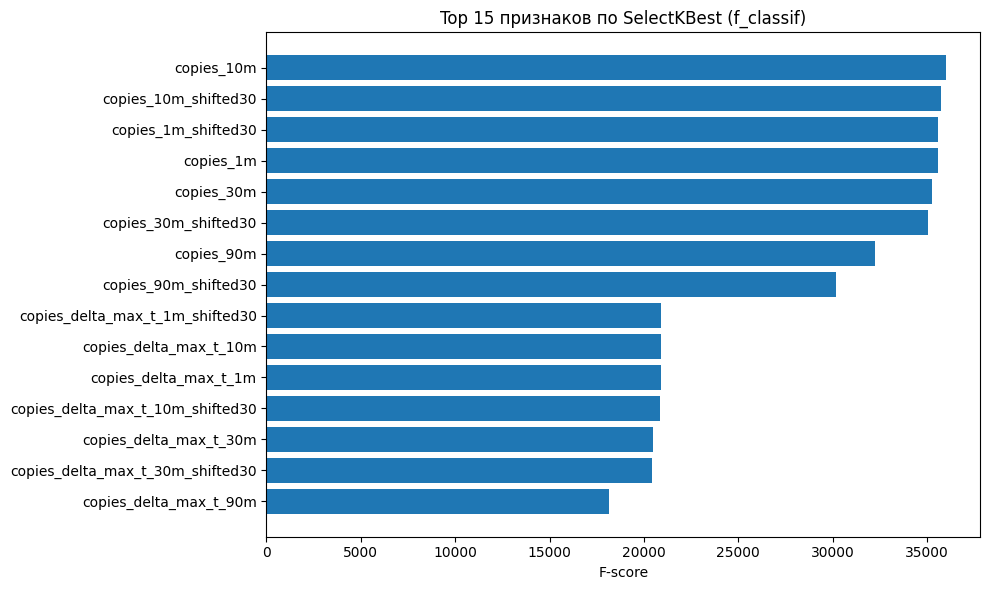

In [20]:
# Напиши код здесь
scores = selector.scores_
feature_names = df_train.drop(columns=['due', 'target', 'city_name']).columns

feat_importance = pd.DataFrame({'feature': feature_names, 'score': scores})
feat_importance = feat_importance.nlargest(15, 'score')

plt.figure(figsize=(10, 6))
plt.barh(range(len(feat_importance)), feat_importance['score'].values)
plt.yticks(range(len(feat_importance)), feat_importance['feature'].values)
plt.xlabel('F-score')
plt.title('Top 15 признаков по SelectKBest (f_classif)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [21]:
# Отбираем признаки на основе  SelectFdr (почитать про него можно тут: https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectFdr.html)

X_clean = df_train.dropna().drop(columns=['due', 'target', 'city_name'])
y_clean = df_train.dropna()['target']

selector = SelectFdr(score_func=f_classif, alpha=0.05)# Напиши код здесь) # p-value задаём как 5%
selector.fit_transform(X_clean, y_clean)# Напиши код здесь

# Проверяем полученное качество модели
start = time.time()
results['f_classif_fdr'] = learn_and_validate(drop_cols=df_train.columns.difference(selector.get_feature_names_out()))
stop = time.time()

metadata['f_classif_fdr'] = [len(selector.get_feature_names_out()), stop-start]

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


ROC AUC на test равен 0.73799
ROC AUC на train равен 0.7345


Теперь алгоритм работает явно дольше, чем при жёстком отборе.

In [22]:
# Посмотрим на выделенные важные признаки
feats = selector.get_feature_names_out()
print(len(feats))
feats

73


array(['dist', 'lat', 'lon', 'econom', 'business', 'vip', 'holiday',
       'cos_weekday', 'cos_daytime', 'dist_MSK', 'is_MSK', 'dist_SPB',
       'is_SPB', 'dist_NN', 'is_NN', 'dist_KAZ', 'is_KAZ', 'dist_VRN',
       'is_VRN', 'knn_1_dist', 'knn_2_dist', 'knn_3_dist', 'knn_5_dist',
       'knn_7_dist', 'knn_10_dist', 'knn_15_dist', 'copies_1m',
       'copies_delta_min_t_1m', 'copies_delta_max_t_1m',
       'copies_1m_shifted30', 'copies_delta_min_t_1m_shifted30',
       'copies_delta_max_t_1m_shifted30', 'copies_10m',
       'copies_delta_min_t_10m', 'copies_delta_max_t_10m',
       'copies_10m_shifted30', 'copies_delta_min_t_10m_shifted30',
       'copies_delta_max_t_10m_shifted30', 'copies_30m',
       'copies_delta_min_t_30m', 'copies_delta_max_t_30m',
       'copies_30m_shifted30', 'copies_delta_min_t_30m_shifted30',
       'copies_delta_max_t_30m_shifted30', 'copies_90m',
       'copies_delta_min_t_90m', 'copies_delta_max_t_90m',
       'copies_90m_shifted30', 'copies_delta_min_

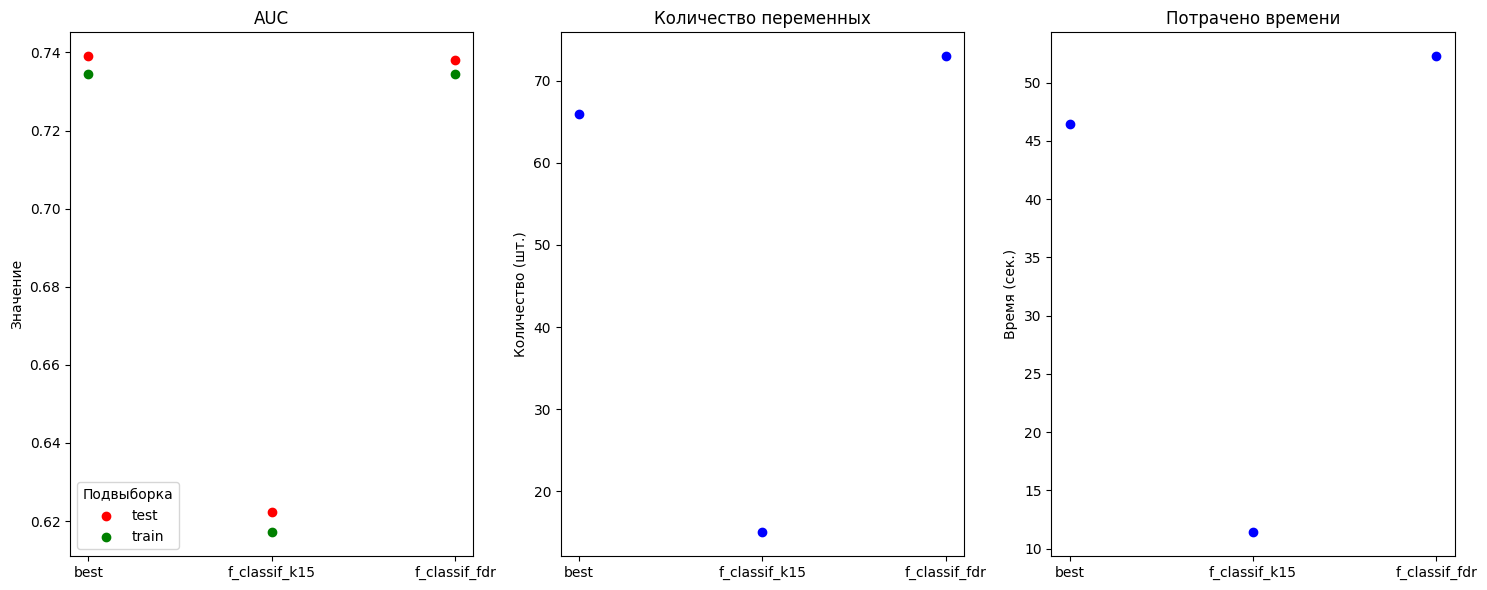

In [23]:
vis_results(results, metadata)

Исключилась часть признаков, которые отвечают за время и похожие заказы, при этом признаки температуры остались. Итоговое качество получилось неплохим, при этом  количество признаков смогли сократить на 15 (до 73).

## Обёртки

> **Обёртки** — это алгоритм некоторого перебора возможных поднаборов признаков, когда с каждым выбранным поднабором модель обучается заново.

Начнём с самого простого способа — последовательного отбора. Данный код работает  долго (можно не запускать).

Этот подход требует много вычислений, так как придётся сделать $\frac{n!}{k!}$ обучений модели, где

n — количество переменных;

k — сколько хотим в итоге отобрать.

Если нет возможности проводить много эксперимантов параллельно, то этот подход нерационален. Но если вдруг в твоей задаче мало переменных (заметим, что сегодня не такой случай), то код у тебя уже есть.

In [24]:
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import TimeSeriesSplit
import warnings
warnings.filterwarnings("ignore", message="X does not have valid feature names")
lgbm_kwargs={'n_estimators': 10, 'n_jobs': -1, 'verbosity': -1,
                                    # 'device': 'gpu',
                                    }

model = LGBMClassifier(**lgbm_kwargs)
cv = TimeSeriesSplit(3) # Сделаем кросс-валидацию по времени, а не обычную

sfs = SequentialFeatureSelector(estimator=model,
                          direction='forward', # Как выбирать, есть ещё backward
                          cv=cv, # Встроенная кросс-валидация для точности отбора. Можно передать число, но тогда будет обычная кросс-валидация, а нам нужна для времени
                          n_features_to_select=25) # Сколько признаков хотим оставить

sfs.fit(df_train.drop(columns=['due', 'target', 'city_name']).values, df_train['target'].values.ravel())
#озу закончилась((((((

KeyboardInterrupt: 

### Задание 2 [4 балла]



Реализуем отбор признаков через Optuna.

Optuna предназначена для умного перебора гиперпараметров. Но выбранное признаковое пространство — это тоже гиперпараметр. Cоздадим бинарный вектор размерности количества переменных в датасете, и Optuna будет подбирать его оптимальные значения.



In [ ]:
# Catboost пригодится для будущих экспериментов, сразу его установим, чтобы потом к этому этапу не возвращаться
!pip install optuna catboost --quiet



Optuna работает быстрее последовательного перебора, но всё же требует времени. Чтобы показать подход, мы ограничим количество итераций. За 25 итераций можно найти качественное подмножество признаков, но мы рассмотрим ещё меньше для экономии времени.



Отбери признаки.
1. С помощью `trial.suggest_categorical` создай бинарный вектор размерности количества переменных.
2. Отфильтруй по нему входные данные.
3. На основе `cross_val_score` получи оценку выбранного поднабора переменных.

In [25]:
import optuna
from sklearn.model_selection import cross_val_score # Обычно тоже используется кросс-валидация для стабильности отбора
from sklearn.model_selection import TimeSeriesSplit

# Можно включить GPU, но для данной задачи получится ускорить всего лишь в два раза, что довольно маленький прирост от GPU
def find_best_features(X=df_train.drop(columns=['due', 'target', 'city_name']),
                       y=df_train['target'].values.ravel(),
                       cv=TimeSeriesSplit(3), scoring='roc_auc', direction='maximize',
                       n_trials=25,
                       lgbm_kwargs={'n_estimators': 100, 'n_jobs': -1, 'verbosity': -1}):
  def objective(trial):
      # Бинарная маска для каждого признака (включён/выключён)
      feature_mask =  [trial.suggest_categorical(f'f_{i}', [0, 1]) for i in range(X.shape[1])]# Напиши код здесь # Создай бинарный вектор

      # Применяем маску к данным
      cols = [c for c, m in zip(X.columns, feature_mask) if m == 1]
      X_selected = X[cols]# Напиши код здесь # Отфильтруй массив

      if X_selected.shape[1] == 0:  # Если ни один признак не выбран
          return 0.0

      # Оцениваем качество модели с выбранными признаками
      model = LGBMClassifier(**lgbm_kwargs)
      # Оцениваем всё по кросс-валидации, чтобы не настраиваться под тест
      score = cross_val_score(model, X_selected, y, cv=cv, scoring=scoring).mean()# Напиши код здесь)

      return score

  # Иницилиазируем Optuna
  study = optuna.create_study(direction=direction)
  # Оптимизируем
  study.optimize(objective, n_trials=n_trials)
  # Возвращаем лучшие отобранные переменные
  return [key for key in study.best_trial.params if study.best_trial.params[key] == 1]

best_features = find_best_features()

[I 2026-04-02 13:41:05,676] A new study created in memory with name: no-name-5f798e3b-3b95-416d-8b13-385d1d2fad41
[I 2026-04-02 13:41:54,617] Trial 0 finished with value: 0.7145409751471861 and parameters: {'f_0': 1, 'f_1': 1, 'f_2': 1, 'f_3': 0, 'f_4': 1, 'f_5': 1, 'f_6': 1, 'f_7': 1, 'f_8': 0, 'f_9': 1, 'f_10': 1, 'f_11': 0, 'f_12': 0, 'f_13': 0, 'f_14': 0, 'f_15': 0, 'f_16': 0, 'f_17': 1, 'f_18': 0, 'f_19': 0, 'f_20': 0, 'f_21': 1, 'f_22': 1, 'f_23': 0, 'f_24': 0, 'f_25': 1, 'f_26': 0, 'f_27': 0, 'f_28': 1, 'f_29': 1, 'f_30': 0, 'f_31': 0, 'f_32': 1, 'f_33': 0, 'f_34': 0, 'f_35': 0, 'f_36': 0, 'f_37': 0, 'f_38': 1, 'f_39': 0, 'f_40': 1, 'f_41': 1, 'f_42': 0, 'f_43': 0, 'f_44': 0, 'f_45': 1, 'f_46': 0, 'f_47': 0, 'f_48': 1, 'f_49': 0, 'f_50': 1, 'f_51': 0, 'f_52': 1, 'f_53': 0, 'f_54': 1, 'f_55': 1, 'f_56': 0, 'f_57': 0, 'f_58': 0, 'f_59': 0, 'f_60': 0, 'f_61': 0, 'f_62': 0, 'f_63': 1, 'f_64': 1, 'f_65': 1, 'f_66': 0, 'f_67': 1, 'f_68': 0, 'f_69': 0, 'f_70': 0, 'f_71': 0, 'f_72': 1, 

In [26]:
len(best_features), best_features

(48,
 ['f_0',
  'f_2',
  'f_3',
  'f_4',
  'f_5',
  'f_8',
  'f_9',
  'f_10',
  'f_11',
  'f_14',
  'f_16',
  'f_17',
  'f_18',
  'f_19',
  'f_22',
  'f_23',
  'f_26',
  'f_27',
  'f_28',
  'f_29',
  'f_31',
  'f_37',
  'f_39',
  'f_42',
  'f_43',
  'f_44',
  'f_47',
  'f_51',
  'f_53',
  'f_56',
  'f_58',
  'f_59',
  'f_60',
  'f_61',
  'f_62',
  'f_64',
  'f_65',
  'f_66',
  'f_69',
  'f_71',
  'f_73',
  'f_76',
  'f_78',
  'f_81',
  'f_82',
  'f_83',
  'f_84',
  'f_85'])



Запуск полного процесса для 25 итераций займёт 20 минут. Чтобы сэкономить время, используем готовый список переменных, сформированный на этапе разработки.

In [27]:
best_features = ['dist', 'lon', 'vip', 'sin_weekday', 'cos_weekday', 'sin_daytime', 'cos_daytime', 'dist_MSK', 'dist_SPB', 'is_SPB', 'dist_NN', 'is_NN', 'dist_VRN', 'knn_1_dist', 'knn_2_dist', 'knn_5', 'knn_7', 'knn_7_dist', 'knn_10_dist', 'knn_15_dist',
                 'copies_1m_shifted30', 'copies_delta_min_t_1m_shifted30', 'copies_delta_max_t_1m_shifted30', 'copies_10m', 'copies_delta_max_t_10m', 'copies_delta_min_t_10m_shifted30', 'copies_30m', 'copies_30m_shifted30', 'copies_delta_min_t_30m_shifted30',
                 'copies_delta_max_t_90m', 'copies_delta_min_t_90m_shifted30', 'copies_delta_max_t_90m_shifted30', 'copies_270m', 'copies_delta_min_t_270m', 'copies_delta_max_t_270m_shifted30', 'temperature_1', 'temperature_2', 'apparent_temperature_2',
                 'temperature_diff_2', 'apparent_temperature_diff_2', 'temperature_3', 'apparent_temperature_3', 'temperature_diff_3', 'apparent_temperature_diff_3', 'temperature_diff_4']



После отбора признаков их количество сократилось вдвое. Переходим к обучению и тестированию модели на финальном наборе признаков.

In [28]:
# Проверяем качество
start = time.time()
results['optuna'] = learn_and_validate(drop_cols=df_train.columns.difference(best_features))
stop = time.time()

metadata['optuna'] = [len(best_features), stop-start]

ROC AUC на test равен 0.73608
ROC AUC на train равен 0.73218


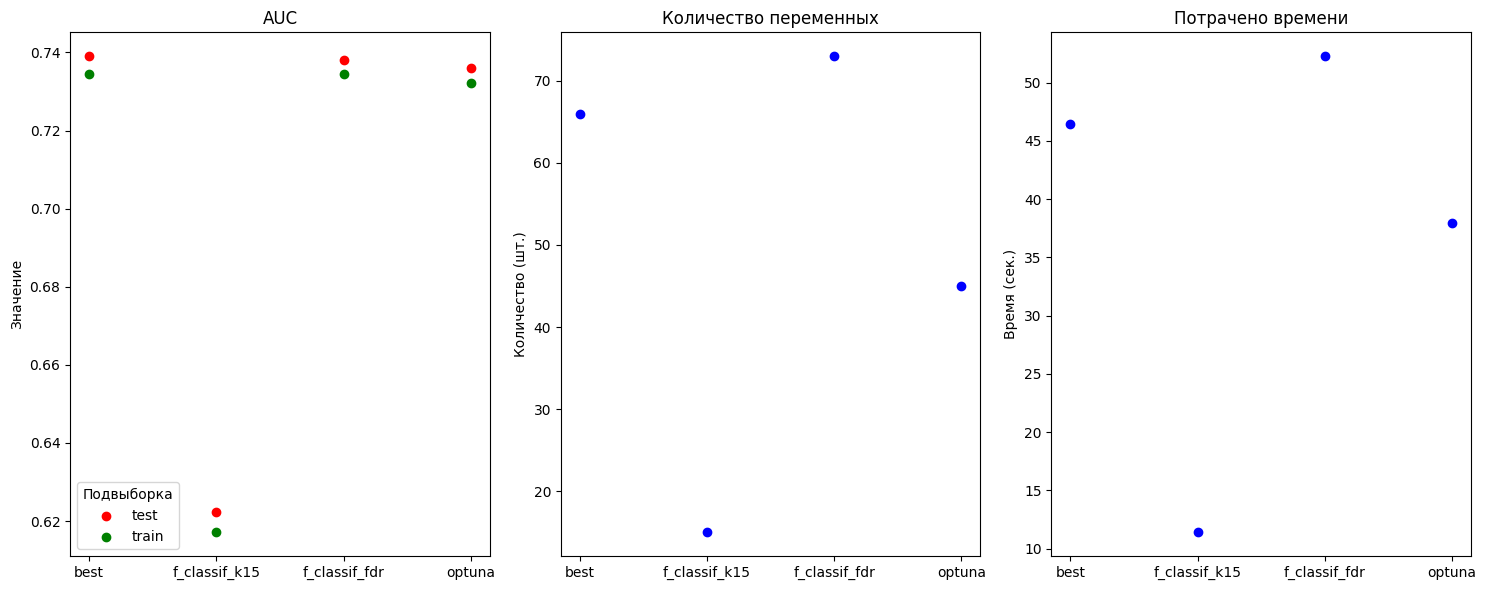

In [29]:
vis_results(results, metadata)



Качество модели снизилось, так как мы исключили часть признаков. Но мы сократили и количество переменных, а это уменьшило расходы на хранение и обработку данных, обучение и инференс моделей.

Теперь перейдём к встроенным методам.

## Встроенные методы

> **Встренные методы** позволяют получать значения важности сразу всех признаков вместе с обучением модели.

Так можно выбрать самые важные признаки по мнению модели сразу после однократного обучения. Но при этом, если обучать на сокращённом признаковом пространстве, важности могут измениться. То есть могут всё равно потребоваться несколько обучений модели.

### Lasso/Ridge


Линейные модели хорошо интерпретируются, поэтому полученные коэффиценты могут описывать важность каждого признака.

Но у каждого признака в необработанном виде свой диапазон значений. Если у признака маленькие значения, а у целевой переменной большие, то, вероятно, при данном признаке получатся большие коэффициенты. Поэтому перед оценкой важности признаков через линейные алгоритмы проводим нормализацию данных.

Будем использовать логистическую регрессию. В реализации sklearn в неё уже встроены штрафы Lasso и Ridge в качестве гиперпараметров.

In [31]:
from sklearn.linear_model import LogisticRegression
# Импортируем класс для нормализации
from sklearn.preprocessing import StandardScaler

In [32]:
# Инициализируем стандартизацию
ss = StandardScaler()
# Сразу удалим nan, потому что логистическая регрессия не умеет с ними работать
df_train_norm = ss.fit_transform(df_train.drop(columns=['due', 'target', 'city_name']).dropna().values)

In [33]:
# По умолчанию регрессия Ridge, max_iter ставим побольше, потому что много данных
model_ridge = LogisticRegression(max_iter=1000, n_jobs=-1)
model_ridge.fit(df_train_norm, df_train.dropna()['target'].values.ravel())

LogisticRegression(max_iter=1000, n_jobs=-1)

Посмотрим на значения коэффицентов, полученных для модели. Выделим самые важные переменные по размеру полученных коэффицентов.

In [34]:
# Выведем в формате (название переменной, важность)
top_columns = [(x, y.item()) for y, x in sorted(zip(np.abs(model_ridge.coef_.ravel()), df_train.drop(columns=['due', 'target', 'city_name']).columns), reverse=True)]

In [35]:
top_columns

[('dist_MSK', 3.744762986870759),
 ('is_MSK', 1.3402274122628979),
 ('is_SPB', 1.0644509486424687),
 ('is_KAZ', 0.737926750272594),
 ('is_NN', 0.4671339198956545),
 ('dist_NN', 0.45698776687586645),
 ('is_VRN', 0.40714227623545146),
 ('dist_VRN', 0.3133432627482502),
 ('knn_10_dist', 0.28468677429485467),
 ('knn_15_dist', 0.2813177820439006),
 ('copies_90m', 0.22088125555835342),
 ('copies_1m_shifted30', 0.19042554518842175),
 ('dist_KAZ', 0.17840692327520427),
 ('dist_SPB', 0.14167401029685864),
 ('knn_7_dist', 0.1286429731743238),
 ('copies_90m_shifted30', 0.1106777021679463),
 ('copies_10m', 0.09561992747459219),
 ('lon', 0.09020029936192878),
 ('cos_daytime', 0.08937857833801384),
 ('vip', 0.08515438459675034),
 ('copies_delta_min_t_30m_shifted30', 0.08395415157169592),
 ('copies_delta_max_t_1m_shifted30', 0.08302241038080002),
 ('copies_270m', 0.08212782481014665),
 ('copies_delta_min_t_1m_shifted30', 0.07524316051503313),
 ('copies_270m_shifted30', 0.07397917064808184),
 ('copies



Модель показала, что признаки города ключевые, а признаки температуры почти не влияют на результат.

Отберём топ-45 переменных и испытаем на них бустинг. Этот алгоритм превосходит логистическую регрессию по мощности и автоматически обрабатывает пропуски в данных.

In [36]:
# Отфильтровываем топ-45 колонок и смотрим, что получилось
cols = [name[0] for name in top_columns[:45]]

start = time.time()
results['ridge'] = learn_and_validate(drop_cols=df_train.columns.difference(cols))
stop = time.time()

metadata['ridge'] = [len(cols), stop-start]

ROC AUC на test равен 0.71056
ROC AUC на train равен 0.70957


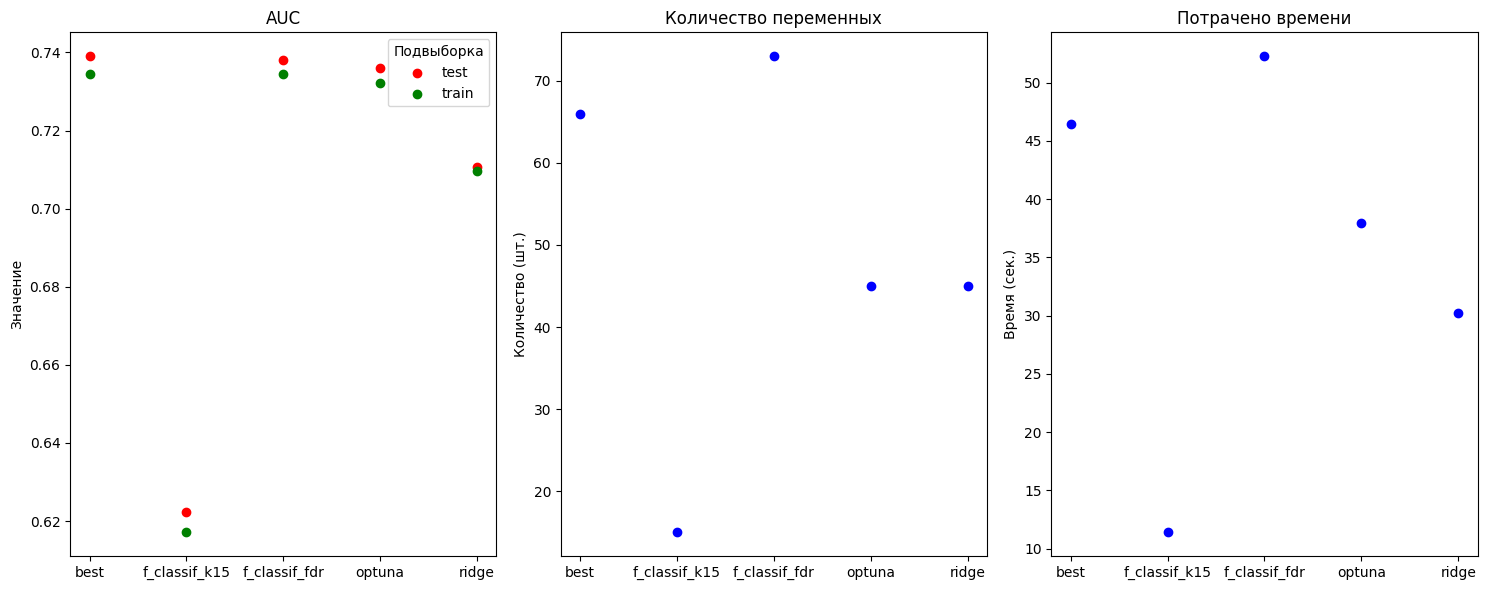

In [37]:
vis_results(results, metadata)

Качество отбора уступает результатам Optuna, но остаётся приемлемым.

Кроме того, полученные веса признаков можно использовать как входные данные для других алгоритмов. Например, для алгоритма градиентного бустинга CatBoost от «Яндекса».  

Посмотрим на конкретный пример реализации.

In [38]:
# Импортируем модель
from catboost import CatBoostClassifier

In [39]:
# Сначала попробуем обучиться без весов переменных
model = CatBoostClassifier(iterations=100, logging_level='Silent')

# Дропаем дату, потому что бустинг с ней не работает в чистом виде
model.fit(df_train.drop(columns=['due', 'city_name', 'target']).values, df_train['target'].values.ravel())

# Делаем предсказание
preds_test = model.predict_proba(df_test.drop(columns=['due', 'city_name', 'target']).values)
preds_train = model.predict_proba(df_train.drop(columns=['due', 'city_name', 'target']).values)

# Считаем метрику
roc_auc_test = roc_auc_score(df_test['target'].values.ravel(), preds_test[:, 1])
roc_auc_train = roc_auc_score(df_train['target'].values.ravel(), preds_train[:, 1])

print(f'ROC AUC на test равен {round(roc_auc_test, 5)}')
print(f'ROC AUC на train равен {round(roc_auc_train, 5)}')

ROC AUC на test равен 0.73537
ROC AUC на train равен 0.73646


In [40]:
# Добавляем веса
model = CatBoostClassifier(iterations=100, feature_weights=np.abs(model_ridge.coef_.ravel()), logging_level='Silent') # Передаем веса в аргумент feature weights

# Дропаем дату, потому что бустинг с ней не работает в чистом виде
model.fit(df_train.drop(columns=['due', 'city_name', 'target']).values, df_train['target'].values.ravel())

# Делаем предсказание
preds_test = model.predict_proba(df_test.drop(columns=['due', 'city_name', 'target']).values)
preds_train = model.predict_proba(df_train.drop(columns=['due', 'city_name', 'target']).values)

# Считаем метрику
roc_auc_test = roc_auc_score(df_test['target'].values.ravel(), preds_test[:, 1])
roc_auc_train = roc_auc_score(df_train['target'].values.ravel(), preds_train[:, 1])

print(f'ROC AUC на test равен {round(roc_auc_test, 5)}')
print(f'ROC AUC на train равен {round(roc_auc_train, 5)}')

ROC AUC на test равен 0.73095
ROC AUC на train равен 0.71899




Качество модели не улучшилось. Возможные причины:
- неоптимальные гиперпараметры;
- модель недообучилась.

> **Примечание.** В практике автора семинара перевзвешивание признаков только один раз привело к значимому приросту качества. Но метод прост в реализации, поэтому его стоит попробовать.

**Что пошло не так.**

При передаче весов из Ridge-модели в бустинг произошла утечка целевой переменной, потому что эти весовые коэффициенты получены по целевой переменной из обучающей выборки.

**Правильный подход.**

Чтобы корректно использовать этот метод, дополнительно раздели данные и выдели отдельную подвыборку только для расчёта весовых коэффициентов.


Попробуем Lasso-регрессию для автоматического отбора признаков. Модель автоматически обнуляет коэффициенты при наименее значимых признаках. Но алгоритм работает долго...

In [41]:
# Меняем штраф на l1, это и есть Lasso. И меняем оптимизатор, потому что стандартный не умеет работать с l1. Работает долго...
model_lasso = LogisticRegression(max_iter=1000, n_jobs=-1, penalty='l1', solver='saga')
model_lasso.fit(df_train_norm, df_train.dropna()['target'].values.ravel())

KeyboardInterrupt: 



Алгоритм работал долго и не достиг оптимального решения. Поэтому логистическую регрессию нечасто применяют на больших данных.

In [42]:
# Выведем в формате (название переменной, важность)
top_columns = [(x, y.item()) for y, x in sorted(zip(np.abs(model_lasso.coef_.ravel()), df_train.drop(columns=['due', 'target', 'city_name']).columns), reverse=True)]

AttributeError: 'LogisticRegression' object has no attribute 'coef_'

In [43]:
top_columns

[('dist_MSK', 3.744762986870759),
 ('is_MSK', 1.3402274122628979),
 ('is_SPB', 1.0644509486424687),
 ('is_KAZ', 0.737926750272594),
 ('is_NN', 0.4671339198956545),
 ('dist_NN', 0.45698776687586645),
 ('is_VRN', 0.40714227623545146),
 ('dist_VRN', 0.3133432627482502),
 ('knn_10_dist', 0.28468677429485467),
 ('knn_15_dist', 0.2813177820439006),
 ('copies_90m', 0.22088125555835342),
 ('copies_1m_shifted30', 0.19042554518842175),
 ('dist_KAZ', 0.17840692327520427),
 ('dist_SPB', 0.14167401029685864),
 ('knn_7_dist', 0.1286429731743238),
 ('copies_90m_shifted30', 0.1106777021679463),
 ('copies_10m', 0.09561992747459219),
 ('lon', 0.09020029936192878),
 ('cos_daytime', 0.08937857833801384),
 ('vip', 0.08515438459675034),
 ('copies_delta_min_t_30m_shifted30', 0.08395415157169592),
 ('copies_delta_max_t_1m_shifted30', 0.08302241038080002),
 ('copies_270m', 0.08212782481014665),
 ('copies_delta_min_t_1m_shifted30', 0.07524316051503313),
 ('copies_270m_shifted30', 0.07397917064808184),
 ('copies

Некоторые погодные переменные имеют очень маленькие коэффициенты: фактически они близки к нулю. Отфильтруем их.


ROC AUC на test равен 0.73802
ROC AUC на train равен 0.73528


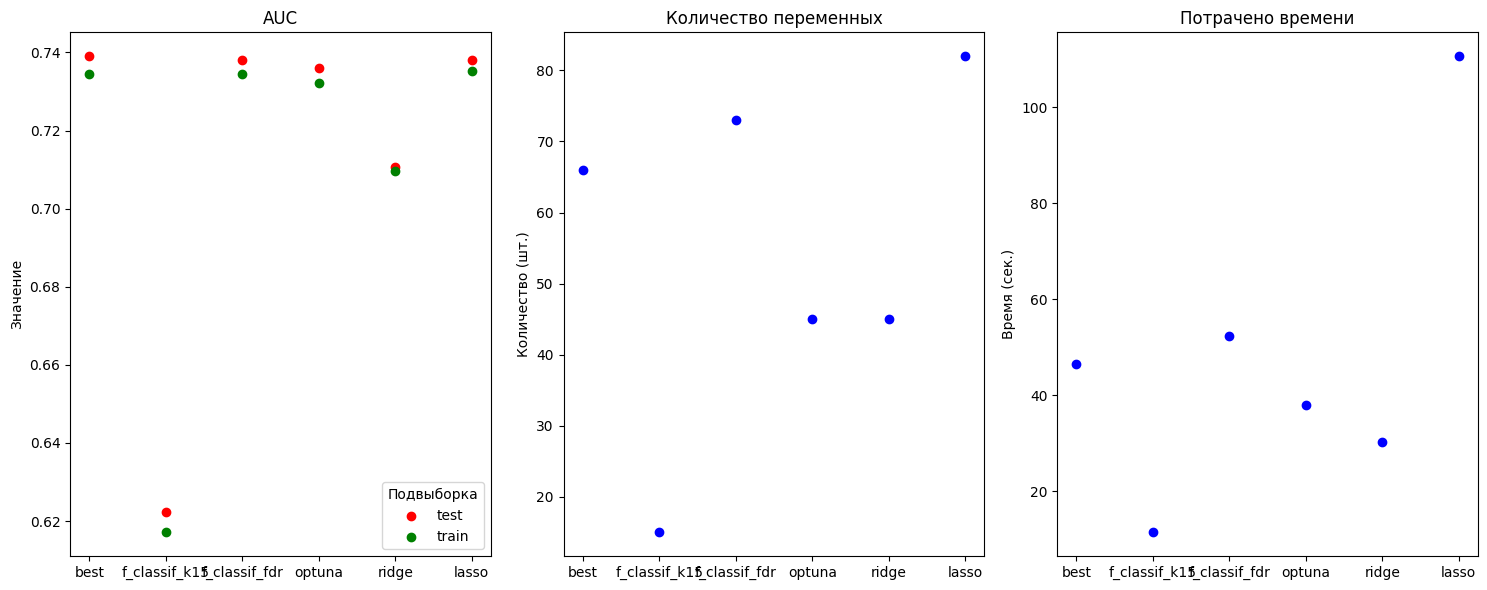

In [44]:
cols = [name[0] for name in top_columns if name[1] > 1e-3]
start = time.time()
results['lasso'] = learn_and_validate(drop_cols=df_train.columns.difference(cols))
stop = time.time()
metadata['lasso'] = [len(cols), stop-start]

vis_results(results, metadata)



Наилучший результат на данный момент мы достигли после исключения части признаков, связанных с температурой.

### Feature importance в древовидных моделях

В процессе обучения древовидные модели выполняют разбиения данных и записывают:
- количество разбиений по каждой переменной,
- общий прирост критерия по итогам всех разбиений по переменной.

Обе метрики оценивают важность признака. Много разбиений или значительное улучшение критерия качества значат, что признак для модели важен.

Рассмотрим, как извлечь эти важности из обученной модели.

In [45]:
# Инициализируем модель
model = LGBMClassifier(n_estimators=100, n_jobs=-1, verbosity=-1)
# Обучаем
model.fit(df_train.drop(columns=['due', 'city_name', 'target']), df_train['target'].values.ravel())

LGBMClassifier(n_jobs=-1, verbosity=-1)

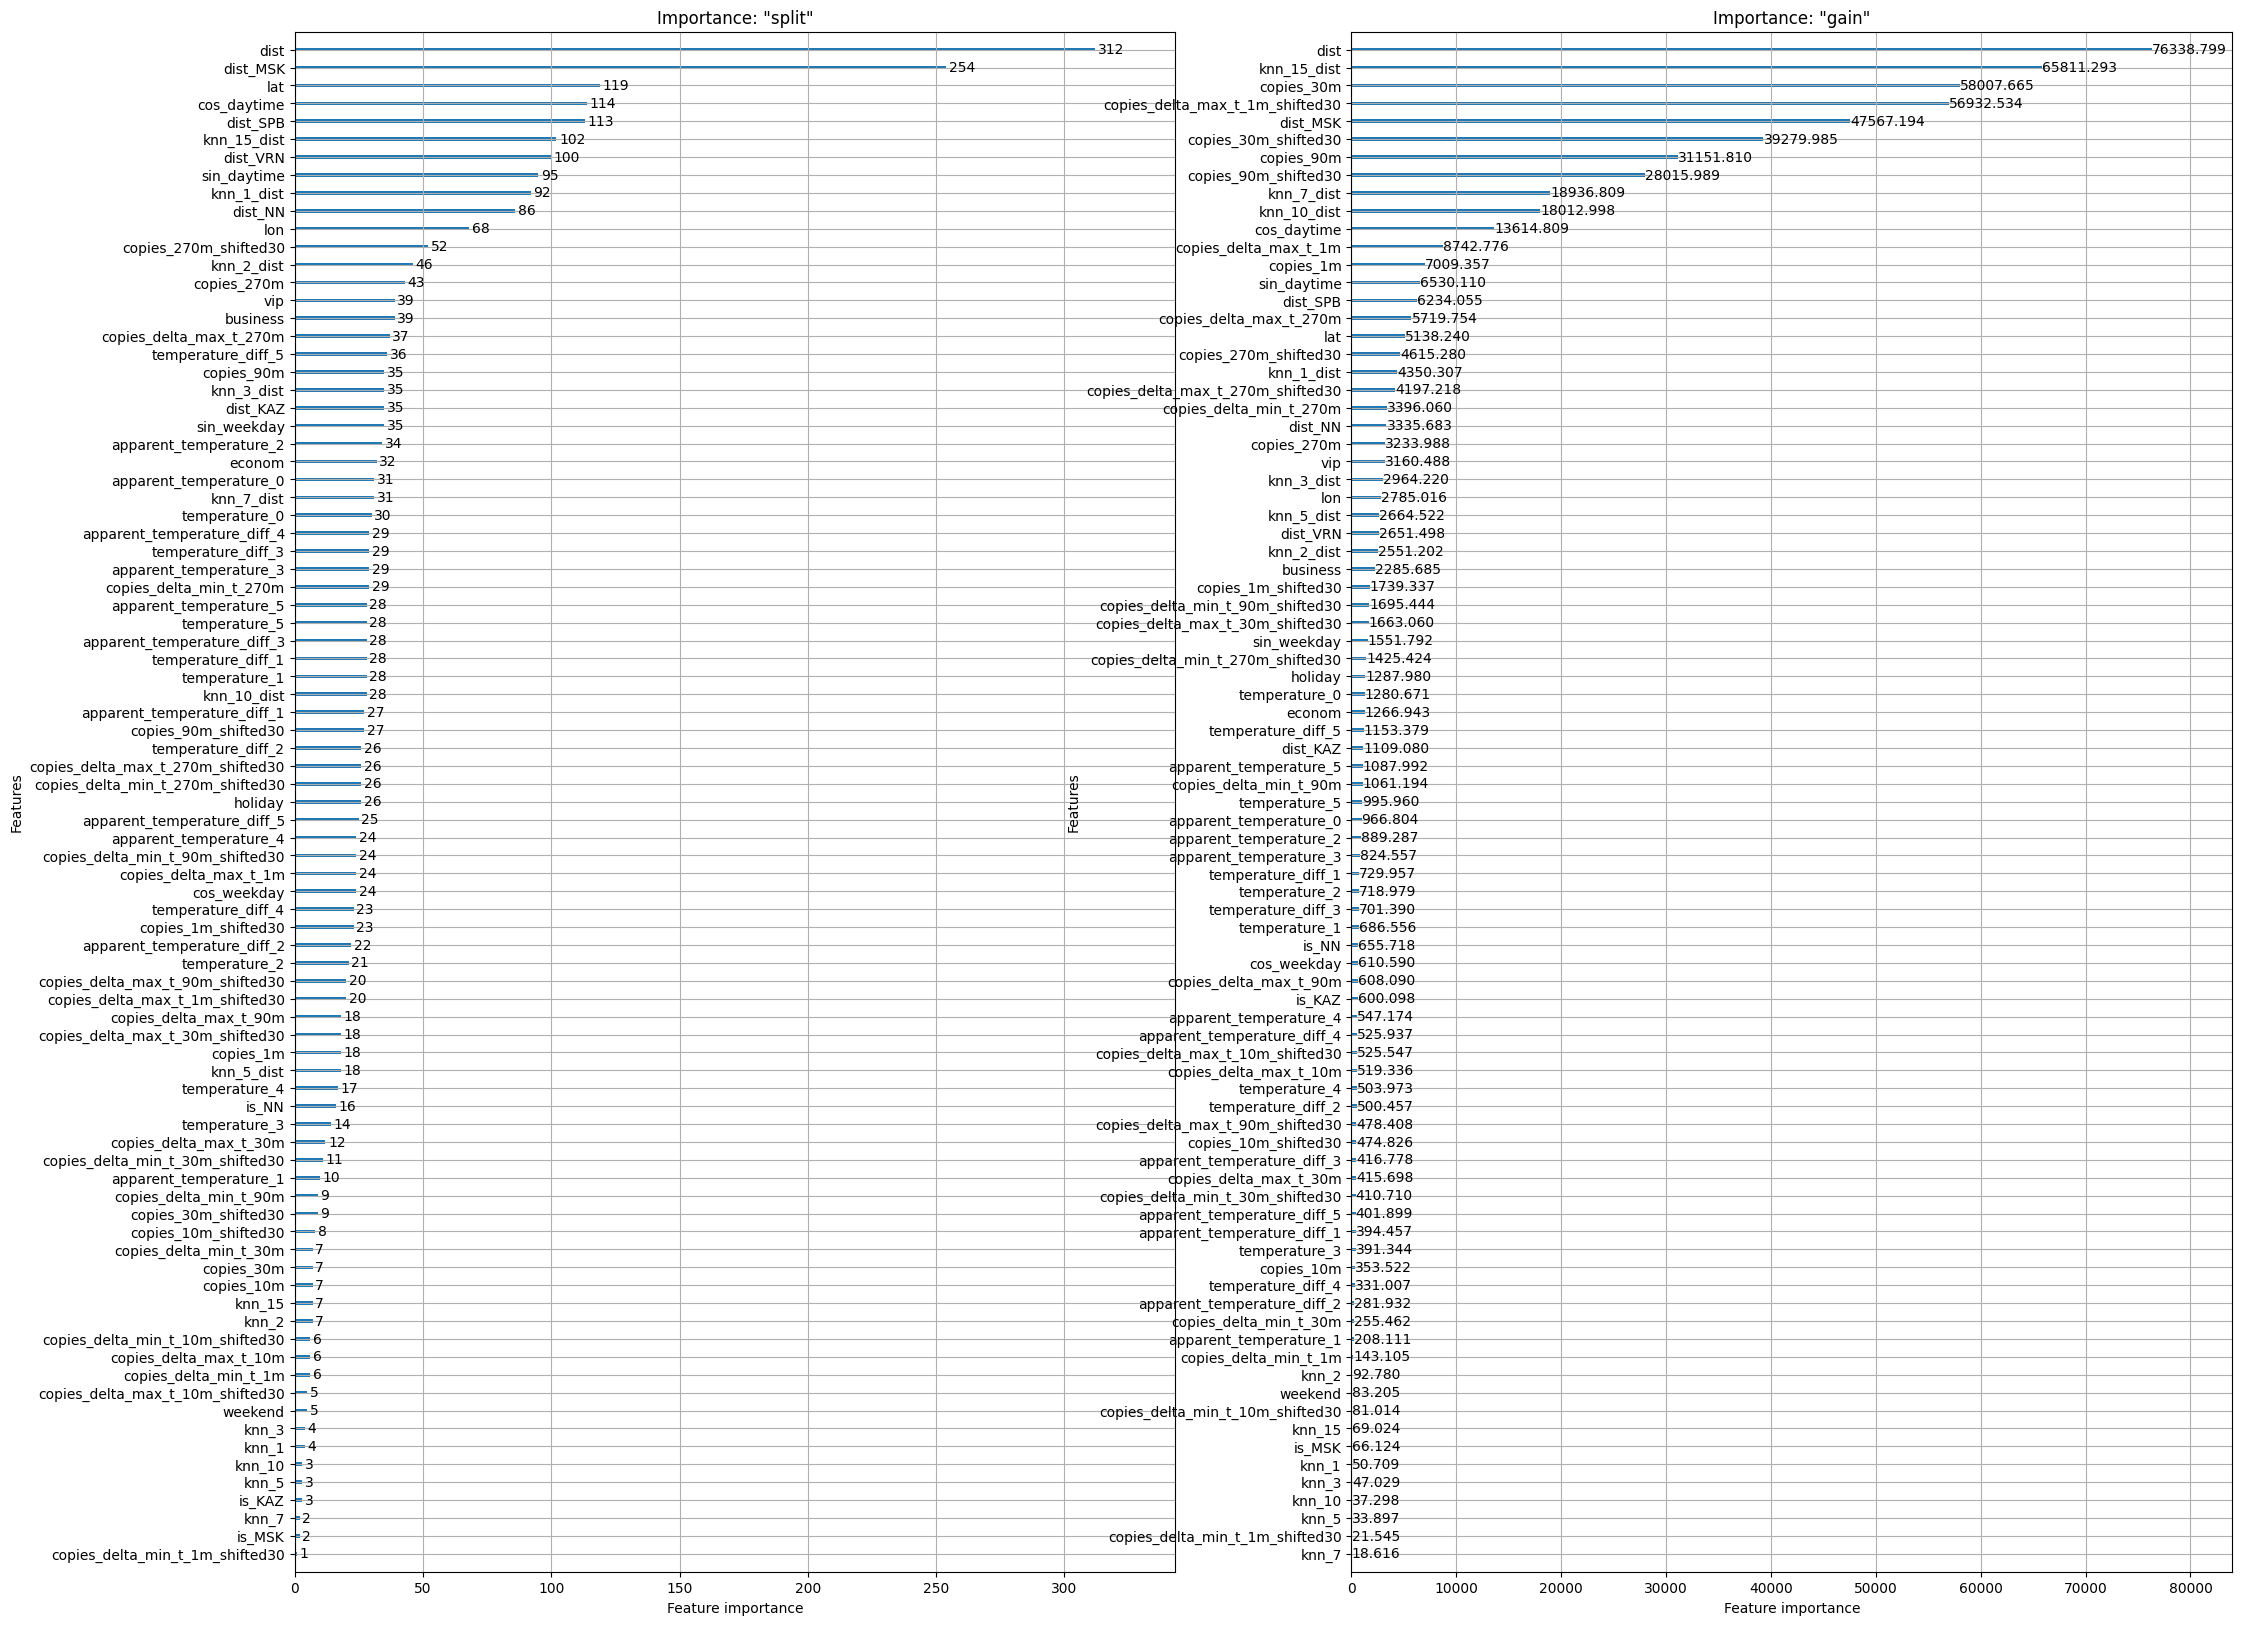

In [46]:
# Выведем визуализации
import lightgbm

fig, axs = plt.subplots(1, 2, figsize=(25, 20))
for ax, imp in zip(axs, ['split', 'gain']):
  lightgbm.plot_importance(model, ax=ax, importance_type=imp, title=f'Importance: "{imp}"')

plt.show()



Для получения численных оценок важности признаков используй функцию `model.booster_.feature_importance()` с параметром `importance_type`, принимающим значения `'split'` или `'gain'`.



Другие библиотеки с деревьями тоже умеют показывать важность признаков.

In [47]:
model.booster_.feature_importance(importance_type='gain')

array([7.63387989e+04, 5.13824018e+03, 2.78501594e+03, 1.26694318e+03,
       2.28568497e+03, 3.16048818e+03, 1.28797998e+03, 8.32050009e+01,
       1.55179170e+03, 6.10589679e+02, 6.53011027e+03, 1.36148089e+04,
       4.75671937e+04, 6.61240997e+01, 6.23405491e+03, 0.00000000e+00,
       3.33568309e+03, 6.55717758e+02, 1.10908014e+03, 6.00097610e+02,
       2.65149781e+03, 0.00000000e+00, 5.07091007e+01, 4.35030665e+03,
       9.27801485e+01, 2.55120217e+03, 4.70286398e+01, 2.96421994e+03,
       3.38965001e+01, 2.66452198e+03, 1.86158504e+01, 1.89368089e+04,
       3.72983007e+01, 1.80129981e+04, 6.90240011e+01, 6.58112931e+04,
       7.00935689e+03, 1.43105167e+02, 8.74277592e+03, 1.73933678e+03,
       2.15454006e+01, 5.69325342e+04, 3.53522007e+02, 0.00000000e+00,
       5.19335691e+02, 4.74826404e+02, 8.10137787e+01, 5.25547493e+02,
       5.80076647e+04, 2.55461585e+02, 4.15698404e+02, 3.92799847e+04,
       4.10710197e+02, 1.66305993e+03, 3.11518105e+04, 1.06119352e+03,
      

<!--Как можно этим пользоваться для отбора признаков?

1. Как и другими методами для отбора признаков. Выбираем топ k лучших или по порогу. Этого мы делать не будем, ты уже опробовал это уже на других методах;
2. Добавляем случайный признак (буквально случайный нормальный вектор) и обучаем вместе с ним алгоритм. Все переменные, важность которых оказалась ниже, чем у случайного вектора, удаляем. Это мы попробуем.
3. Случайным образом перемешиваем одну переменную. Если после обучения ее важность практически не изменилась, эта переменная не особо важная. Это тоже попробуем.-->

Стратегии отбора признаков на основе важности


1. Признаки выбираются на основе ранжирования: или топ-k признаков с наибольшей важностью, или признаки с порогом минимальной значимости. Такую стратегию мы уже пробовали на других алгоритмах.

2. В набор данных добавляется случайный признак (случайный нормальный вектор). После обучения модели удаляются все признаки, важность которых оказалась ниже, чем у данного случайного признака. Эту стратегию будем проверять в 3-м задании.

3. Случайным образом перемешиваем одну переменную. Если важность признака после перестановки статистически значимо не уменьшается, значит, переменная неважна. Этот подход также будем тестировать после 3-го задания.

### Задание 3 [3 балл]

1. Добавь новую случайную нормальную переменную.
2. Получи важность признаков.
3. Оставь только те признаки, важность которых выше, чем у случайных.

ROC AUC на test равен 0.73833
ROC AUC на train равен 0.7354


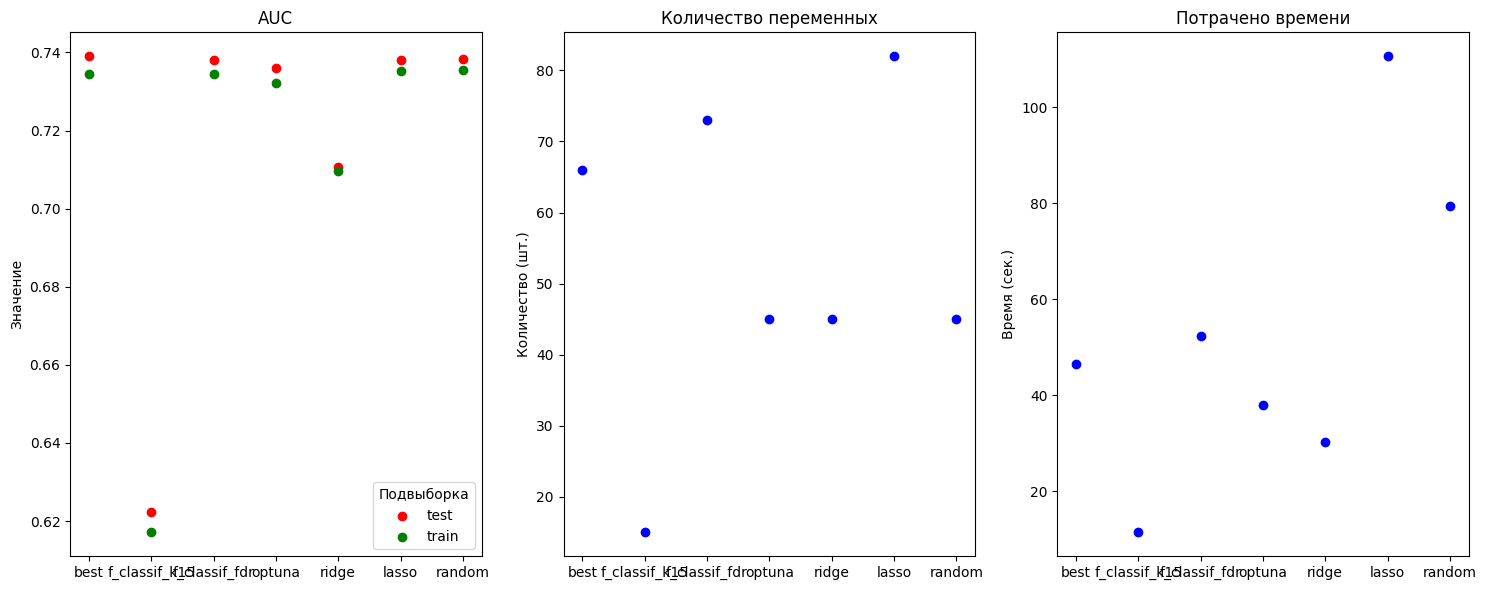

In [50]:
# Добавляем новую случайную нормальную переменную
np.random.seed(123) # Зафиксируем сид для повторяемости эксперимента
df_train['random'] = np.random.randn(len(df_train))# Напиши код здесь
# Обучаемся
model = LGBMClassifier(n_estimators=100, n_jobs=-1, verbosity=-1)
model.fit(df_train.drop(columns=['due', 'city_name', 'target']), df_train['target'].values.ravel())

# Получаем важности
importances =  pd.Series(model.feature_importances_,
                         index=df_train.drop(columns=['due', 'city_name', 'target']).columns)# Напиши код здесь

# Отфильтровываем переменные, важность которых ниже, чем у случайных
feats = importances[importances >= importances['random']].index.tolist()# Напиши код здесь

# Дропаем случайную колонку
df_train.drop(columns='random', inplace=True)

# Обучаемся на новом поднаборе признаков
start = time.time()
results['random'] = learn_and_validate(drop_cols=df_train.columns.difference(feats))
stop = time.time()
metadata['random'] = [len(best_features), stop-start]

vis_results(results, metadata)

In [51]:
feats

['dist',
 'lat',
 'lon',
 'econom',
 'business',
 'vip',
 'holiday',
 'sin_weekday',
 'cos_weekday',
 'sin_daytime',
 'cos_daytime',
 'dist_MSK',
 'dist_SPB',
 'dist_NN',
 'dist_KAZ',
 'dist_VRN',
 'knn_1_dist',
 'knn_2_dist',
 'knn_3_dist',
 'knn_7_dist',
 'knn_10_dist',
 'knn_15_dist',
 'copies_delta_max_t_1m',
 'copies_1m_shifted30',
 'copies_90m',
 'copies_90m_shifted30',
 'copies_delta_min_t_90m_shifted30',
 'copies_270m',
 'copies_delta_min_t_270m',
 'copies_delta_max_t_270m',
 'copies_270m_shifted30',
 'copies_delta_min_t_270m_shifted30',
 'copies_delta_max_t_270m_shifted30',
 'temperature_0',
 'apparent_temperature_0',
 'temperature_1',
 'temperature_diff_1',
 'apparent_temperature_diff_1',
 'apparent_temperature_2',
 'temperature_diff_2',
 'apparent_temperature_diff_2',
 'apparent_temperature_3',
 'temperature_diff_3',
 'apparent_temperature_diff_3',
 'temperature_4',
 'apparent_temperature_4',
 'apparent_temperature_diff_4',
 'temperature_5',
 'apparent_temperature_5',
 'temp



У нас теперь 17 переменных. Мы несильно потеряли в качестве по сравнению с эталонным решением, но такое количество переменных влияет на скорость работы.  

Чтобы сократить количество признаков, можно многократно обучать модель с разными значениями `seed`. Так мы исключим дополнительные переменные.

**Перемешаем одну переменную**



 Применяем `np.random.permutation` и оцениваем изменение признака на графиках, а не по численным значениям.

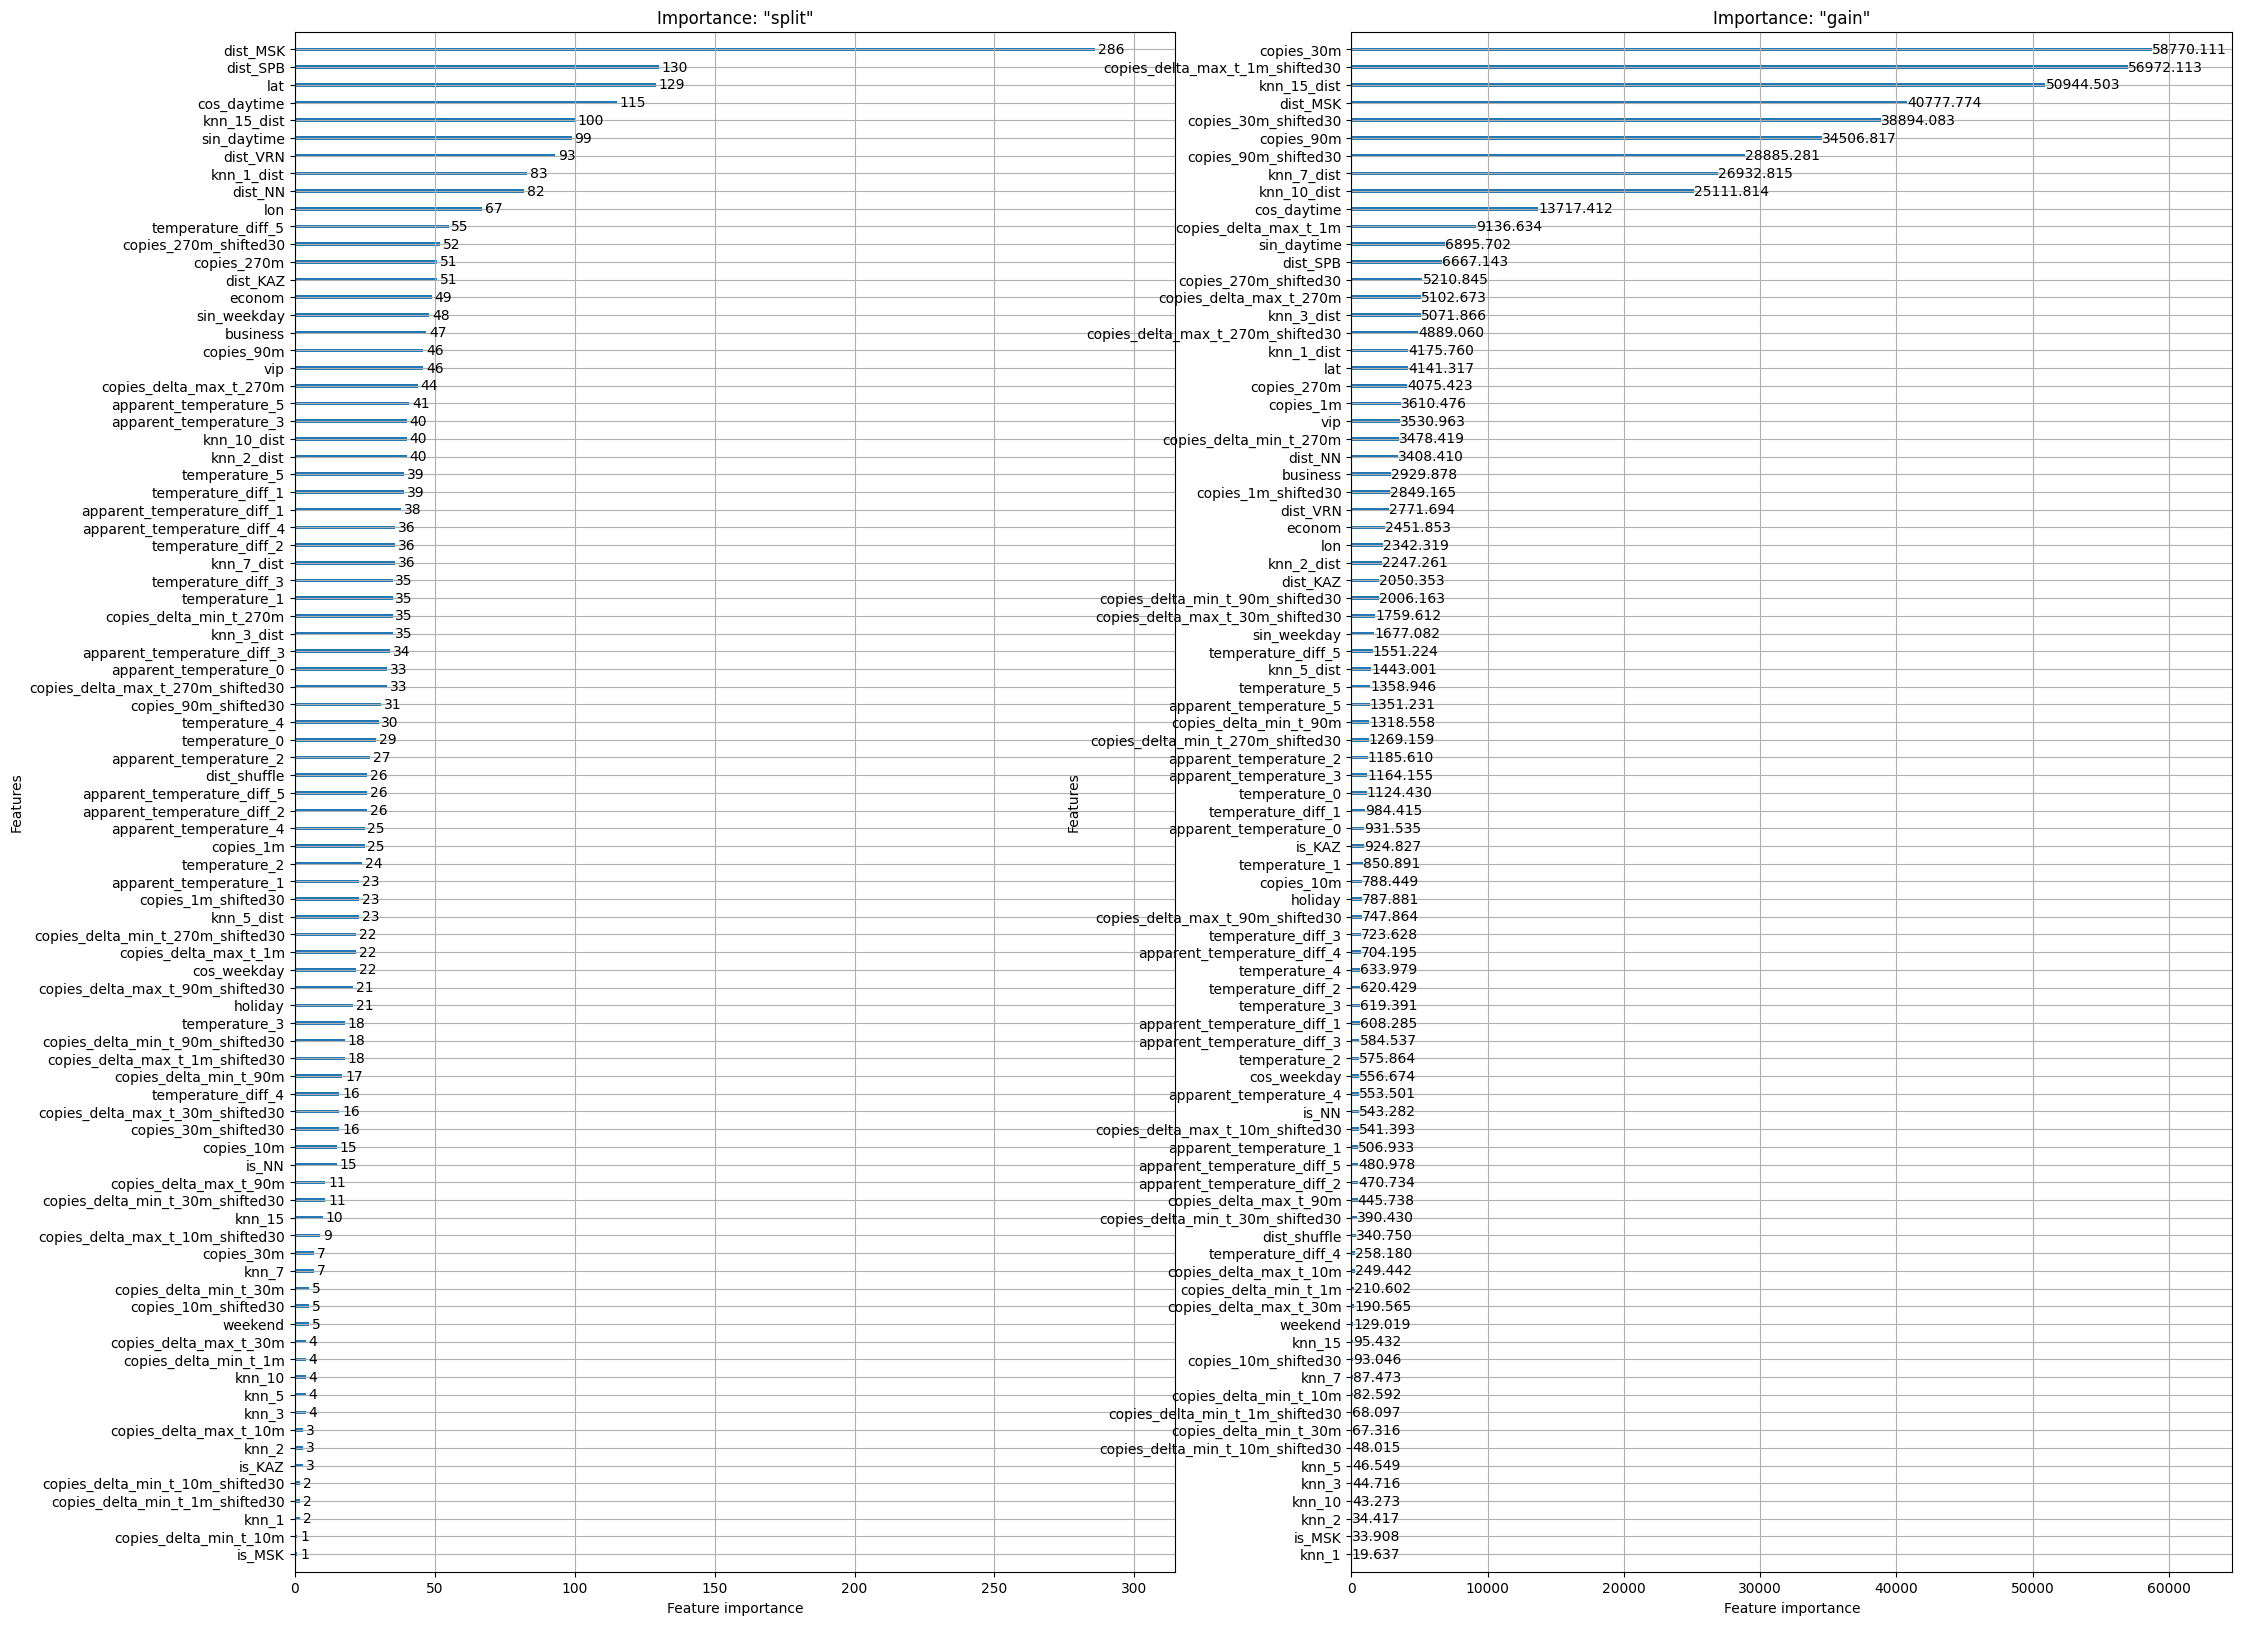

In [52]:
# Начнём с заведомо важной переменной dist
df_train['dist_shuffle'] = np.random.permutation(df_train['dist'].values)

# Обучимся с данной переменной
model = LGBMClassifier(n_estimators=100, n_jobs=-1, verbosity=-1)
model.fit(df_train.drop(columns=['due', 'city_name', 'target', 'dist']), df_train['target'].values.ravel())

# Визуализируем
fig, axs = plt.subplots(1, 2, figsize=(25, 20))
for ax, imp in zip(axs, ['split', 'gain']):
  lightgbm.plot_importance(model, ax=ax, importance_type=imp, title=f'Importance: "{imp}"')

plt.show()

# Удалим добавленную переменную
df_train.drop(columns='dist_shuffle', inplace=True)

Важность переменной существенно снизилась. Значит, она была важной.

Теперь попробуем с менее важной переменной. Например, `temperature_diff_4`.

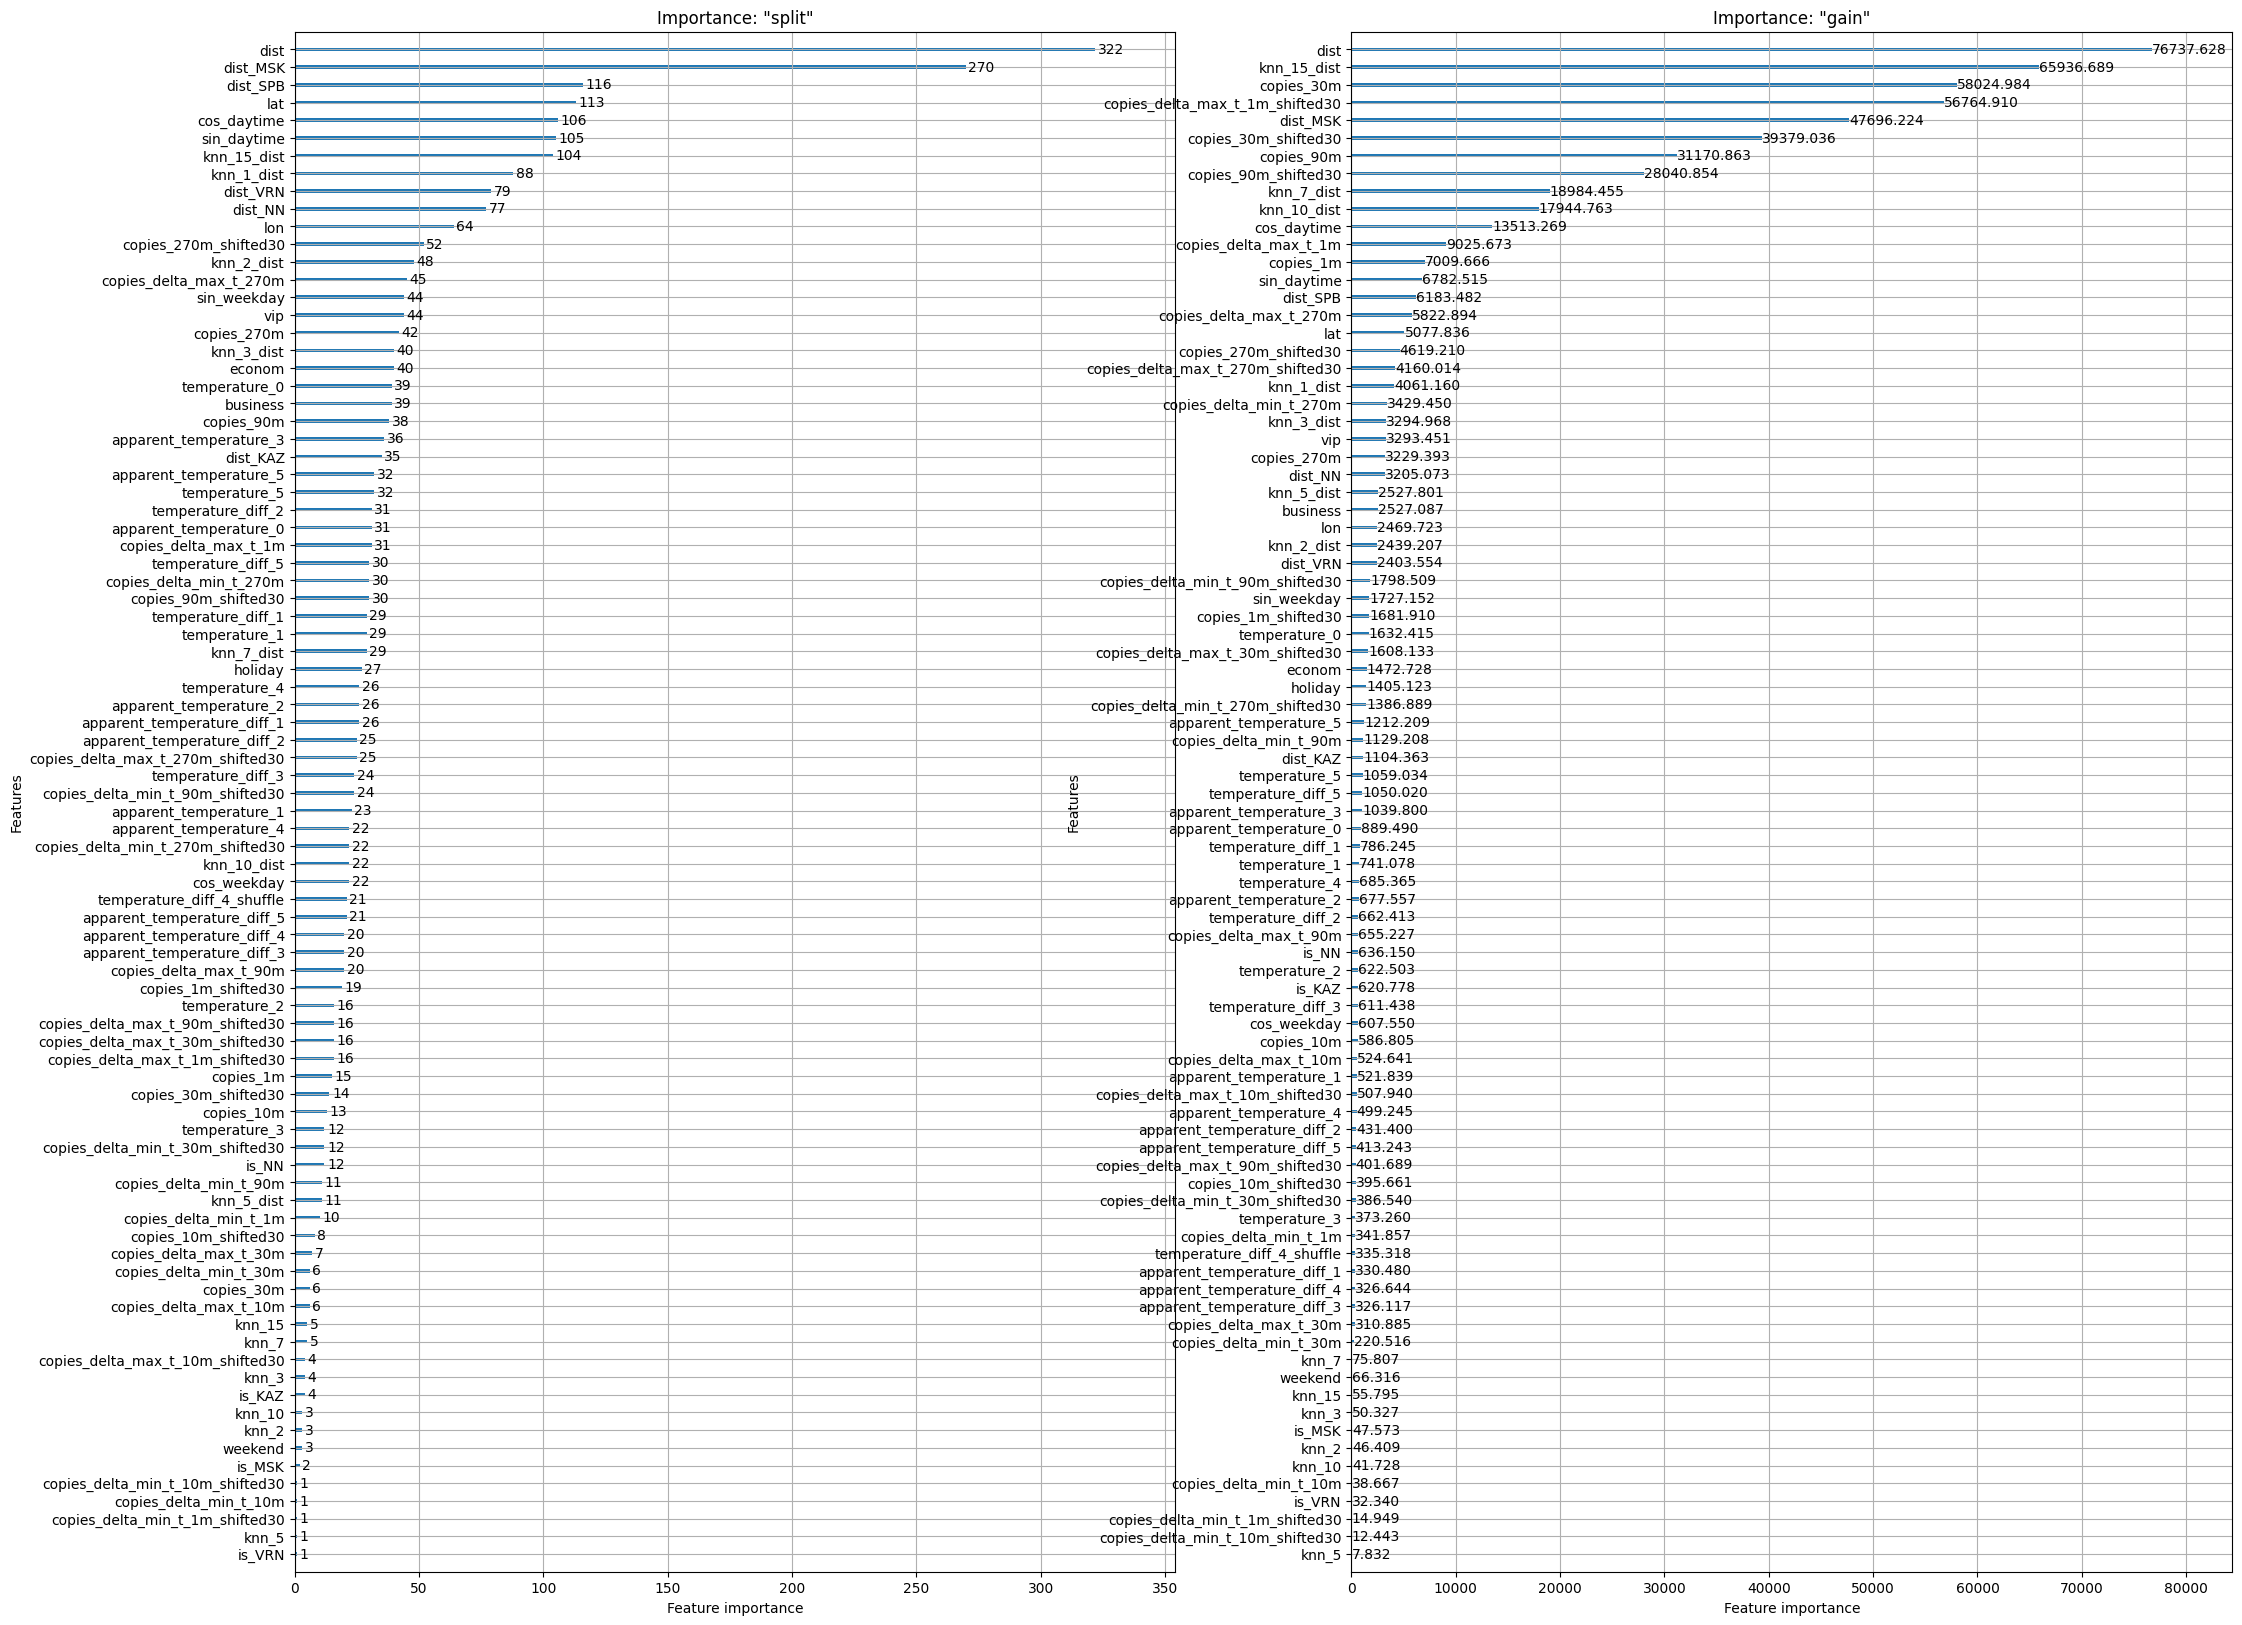

In [53]:
# Теперь выберем заведомо неважную переменную temperature_diff_4_shuffle
df_train['temperature_diff_4_shuffle'] = np.random.permutation(df_train['temperature_diff_4'].values)

# Обучимся с данной переменной
model = LGBMClassifier(n_estimators=100, n_jobs=-1, verbosity=-1)
model.fit(df_train.drop(columns=['due', 'city_name', 'target', 'temperature_diff_4']), df_train['target'].values.ravel())

# Визуализируем
fig, axs = plt.subplots(1, 2, figsize=(25, 20))
for ax, imp in zip(axs, ['split', 'gain']):
  lightgbm.plot_importance(model, ax=ax, importance_type=imp, title=f'Importance: "{imp}"')

plt.show()

# Удалим добавленную переменную
df_train.drop(columns='temperature_diff_4_shuffle', inplace=True)



Важность переменной стала только больше, значит, её можно исключать. Как и в методе случайной переменной, признаки, важность которых возрастает после перестановки, неинформативны и подлежат исключению.

##Итоги отбора признаков







### Задание 4 [2 балла (бонус)]


Подведи итоги отбора признаков. Какие методы хорошо отработали для твоей задачи, а какие не очень.

наиболее сбалансированным решением оказался метод случайной переменной. Он ускорил обучение и упростил интерпретацию. Методы-фильтры оказались слишком грубыми, а Optuna – избыточно затратным по времени при минимальном приросте метрики.


###Как выбрать метод для отбора признаков


| Цель | Оптимальный метод | Суть метода | Плюсы | Минусы |
|---------------|--------------|-------------|-------|---------|
| Максимальное качество | Прямой отбор  | Ручной выбор всех потенциально полезных признаков | Наивысшее качество модели | Большое количество переменных, медленная работа |
| Баланс качества и эффективности | Методы-обёртки (например, Optuna) | Умный перебор комбинаций признаков с оценкой качества | Оптимальное соотношение, меньше признаков | Вычислительно затратно, требует времени |
| Простота и интерпретируемость | Встроенные методы (`feature_importance`, Lasso) | Отбор «встроен» в процесс обучения модели | Быстро, не требует дополнительных вычислений | Качество зависит от алгоритма, возможны потери в точности |
| Скорость (предварительный анализ) | Методы-фильтры (статистические) | Быстрая оценка признаков дообучения модели | Очень быстрый, независим от модели | Низкое качество отбора, может пропустить важные связи |



## Теперь ты умеешь

- Применять методы-фильтры для быстрого отбора переменных.

- Использовать методы-обёртки.

- Использовать встроенные методы, такие как Lasso, Ridge и анализ `feature_importance` в деревьях.

- Применять ансамблевые подходы, комбинируя несколько методов для надёжного результата.


